# Network Intrusion Detection with Machine Learning
**Information Security · Assignment 1 · CLO 4**  
Moaz Sarwar

Build a simple security tool for SecureNet Corp. A Random Forest labels a connection as **normal (0)** or **attack (1)**. This notebook contains the full workflow. Run cells from top to bottom. The final section replays stored records; it does not capture live packets.

We use the published NSL-KDD 20% training file and the full supplied test file. These are historical benchmark connections, not current production traffic. References and exact dataset provenance are in `data/README.md`.

In [1]:
from pathlib import Path
import json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Run the notebook in the project root, or run src/train.py from any directory.
ROOT = Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd()
DATA = ROOT / 'data'
for folder in ['results', 'images', 'models']:
    (ROOT / folder).mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
print('scikit-learn:', sklearn.__version__)


scikit-learn: 1.8.0


## 1 Problem and data setup
NSL-KDD represents normal connections and attacks such as denial of service, scanning and unauthorized access. Each row has 41 input features, an attack name and a difficulty value. The final two columns must never be model inputs. We use the ready-made train/test split and do not mix it.

In [2]:
FEATURES = """duration protocol_type service flag src_bytes dst_bytes land wrong_fragment urgent hot num_failed_logins logged_in num_compromised root_shell su_attempted num_root num_file_creations num_shells num_access_files num_outbound_cmds is_host_login is_guest_login count srv_count serror_rate srv_serror_rate rerror_rate srv_rerror_rate same_srv_rate diff_srv_rate srv_diff_host_rate dst_host_count dst_host_srv_count dst_host_same_srv_rate dst_host_diff_srv_rate dst_host_same_src_port_rate dst_host_srv_diff_host_rate dst_host_serror_rate dst_host_srv_serror_rate dst_host_rerror_rate dst_host_srv_rerror_rate""".split()
CATEGORIES = ['protocol_type', 'service', 'flag']
NUMERIC = [c for c in FEATURES if c not in CATEGORIES]
COLUMNS = FEATURES + ['attack_name', 'difficulty']

def load_data(filename):
    frame = pd.read_csv(DATA / filename, header=None)
    if frame.shape[1] != 43:
        raise ValueError(f'{filename}: expected 43 columns, got {frame.shape[1]}')
    frame.columns = COLUMNS
    if frame['attack_name'].isna().any():
        raise ValueError('Missing target labels cannot be imputed.')
    frame['attack_name'] = frame['attack_name'].str.strip().str.rstrip('.')
    for column in NUMERIC:
        frame[column] = pd.to_numeric(frame[column], errors='raise')
    frame[NUMERIC] = frame[NUMERIC].replace([np.inf, -np.inf], np.nan)
    return frame

train = load_data('KDDTrain+_20Percent.txt')
test = load_data('KDDTest+.txt')
assert len(train) == 25192 and len(test) == 22544
# Diagnose repeated feature records before training. Retain benchmark test rows.
audit = {
    'train_rows_raw': len(train), 'test_rows': len(test),
    'train_missing_feature_values': int(train[FEATURES].isna().sum().sum()),
    'test_missing_feature_values': int(test[FEATURES].isna().sum().sum()),
    'train_duplicate_feature_rows': int(train.duplicated(FEATURES).sum()),
    'test_duplicate_feature_rows': int(test.duplicated(FEATURES).sum()),
}
train = train.drop_duplicates(subset=FEATURES, keep='first').reset_index(drop=True)
train_hash = pd.util.hash_pandas_object(train[FEATURES], index=False)
test_hash = pd.util.hash_pandas_object(test[FEATURES], index=False)
audit['test_rows_matching_train_features'] = int(test_hash.isin(set(train_hash)).sum())
# Do not train on any feature record that appears in the supplied test set.
train = train.loc[~train_hash.isin(set(test_hash))].reset_index(drop=True)
audit['train_rows_used'] = len(train)
X_train, X_test = train[FEATURES], test[FEATURES]
y_train = (train['attack_name'] != 'normal').astype(int)
y_test = (test['attack_name'] != 'normal').astype(int)
assert list(X_train.columns) == FEATURES
assert 'difficulty' not in X_train and 'attack_name' not in X_train
print(json.dumps(audit, indent=2))
print(X_train.head(3).to_string(index=False))


{
  "train_rows_raw": 25192,
  "test_rows": 22544,
  "train_missing_feature_values": 0,
  "test_missing_feature_values": 0,
  "train_duplicate_feature_rows": 1,
  "test_duplicate_feature_rows": 57,
  "test_rows_matching_train_features": 118,
  "train_rows_used": 25074
}
 duration protocol_type  service flag  src_bytes  dst_bytes  land  wrong_fragment  urgent  hot  num_failed_logins  logged_in  num_compromised  root_shell  su_attempted  num_root  num_file_creations  num_shells  num_access_files  num_outbound_cmds  is_host_login  is_guest_login  count  srv_count  serror_rate  srv_serror_rate  rerror_rate  srv_rerror_rate  same_srv_rate  diff_srv_rate  srv_diff_host_rate  dst_host_count  dst_host_srv_count  dst_host_same_srv_rate  dst_host_diff_srv_rate  dst_host_same_src_port_rate  dst_host_srv_diff_host_rate  dst_host_serror_rate  dst_host_srv_serror_rate  dst_host_rerror_rate  dst_host_srv_rerror_rate
        0           tcp ftp_data   SF        491          0     0               0    

## 2 Explore the traffic
Count normal and malicious records, examine the most common training attack names, and inspect numeric values. The training charts describe what the model can learn. The separate test distribution shows how its evaluation traffic differs.

             Training   Test
attack_name                 
Normal          13426   9711
Attack          11648  12833

Numeric summary:
       duration     src_bytes   dst_bytes     count
count  25074.00  2.507400e+04    25074.00  25074.00
mean     306.49  2.444141e+04     3507.90     84.32
std     2692.79  2.416471e+06    89039.18    114.43
min        0.00  0.000000e+00        0.00      1.00
25%        0.00  0.000000e+00        0.00      2.00
50%        0.00  4.400000e+01        0.00     14.00
75%        0.00  2.790000e+02      544.75    143.00
max    42862.00  3.817091e+08  5151385.00    511.00


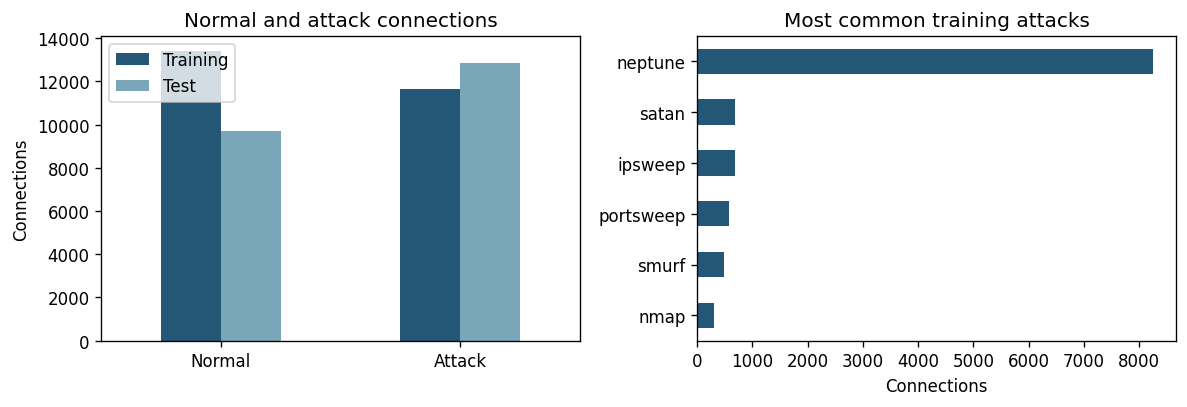

In [3]:
counts = pd.DataFrame({'Training': y_train.value_counts(), 'Test': y_test.value_counts()}).fillna(0).astype(int)
counts.index = counts.index.map({0: 'Normal', 1: 'Attack'})
print(counts.to_string())
print('\nNumeric summary:')
print(X_train[['duration', 'src_bytes', 'dst_bytes', 'count']].describe().round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts.plot.bar(ax=axes[0], color=['#245675', '#79a6b9'], rot=0)
axes[0].set(title='Normal and attack connections', ylabel='Connections', xlabel='')
train.loc[train.attack_name != 'normal', 'attack_name'].value_counts().head(6).sort_values().plot.barh(ax=axes[1], color='#245675')
axes[1].set(title='Most common training attacks', xlabel='Connections', ylabel='')
fig.tight_layout()
fig.savefig(ROOT / 'images/eda.png', dpi=170)
plt.show()


## 3 Prepare and train the model
Missing numerical values are replaced by training medians; missing categories use the most common training value. One-hot encoding makes separate indicator columns for protocol, service and flag. Unknown test categories are ignored safely. StandardScaler subtracts the training mean and divides by the training standard deviation. Scaling is included to meet the assignment; Random Forest itself does not require it.

A pipeline fits every preprocessing step **only on training data**. The forest uses 100 trees, maximum depth 20, minimum leaf size 2, balanced class weights and seed 42. These settings are fixed in advance, not selected by repeated test-set experiments. Trees learn different rules and their probabilities are averaged. This is a simple CPU model suited to mixed network features.

In [4]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
category_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, NUMERIC),
    ('categorical', category_pipeline, CATEGORIES),
])
model = Pipeline([
    ('preprocess', preprocessor),
    ('forest', RandomForestClassifier(n_estimators=100, max_depth=20,
        min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=-1)),
])
start = time.perf_counter()
model.fit(X_train, y_train)
training_seconds = time.perf_counter() - start
print(f'Trained on {len(X_train):,} connections in {training_seconds:.2f} seconds.')
print('Encoded input columns:', len(model['preprocess'].get_feature_names_out()))


Trained on 25,074 connections in 0.42 seconds.
Encoded input columns: 117


## 4 Evaluate on unseen connections
Attack is the positive class. Precision answers “Of the alerts raised, how many were real attacks?” Recall answers “Of the actual attacks, how many did we detect?” False negatives are missed attacks; false positives are normal connections that create false alarms. Accuracy alone cannot show these two risks.

              precision    recall  f1-score   support

      Normal     0.6465    0.9725    0.7767      9711
      Attack     0.9664    0.5976    0.7385     12833

    accuracy                         0.7591     22544
   macro avg     0.8064    0.7851    0.7576     22544
weighted avg     0.8286    0.7591    0.7549     22544

False alarms: 267; missed attacks: 5,164
Always-normal baseline accuracy: 43.08%


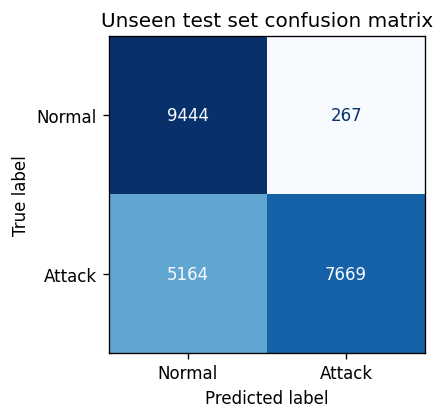

In [5]:
start = time.perf_counter()
y_pred = model.predict(X_test)
prediction_seconds = time.perf_counter() - start
report = classification_report(y_test, y_pred, labels=[0, 1], target_names=['Normal', 'Attack'], output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = [int(v) for v in cm.ravel()]
metrics = {
    'accuracy': float(accuracy_score(y_test, y_pred)),
    'attack_precision': report['Attack']['precision'],
    'attack_recall': report['Attack']['recall'],
    'attack_f1': report['Attack']['f1-score'],
    'false_positive_rate': fp / (fp + tn),
    'miss_rate': fn / (fn + tp),
    'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
    'training_seconds': training_seconds, 'batch_prediction_seconds': prediction_seconds,
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'always_normal_accuracy': float((y_test == 0).mean()),
    'sklearn_version': sklearn.__version__, 'seed': SEED,
}
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['Normal', 'Attack'], digits=4, zero_division=0))
print(f'False alarms: {fp:,}; missed attacks: {fn:,}')
print(f'Always-normal baseline accuracy: {metrics["always_normal_accuracy"]:.2%}')
fig, ax = plt.subplots(figsize=(5.3, 3.6))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Attack']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Unseen test set confusion matrix')
fig.tight_layout()
fig.savefig(ROOT / 'images/confusion_matrix.png', dpi=170)
plt.show()
(ROOT / 'results/metrics.json').write_text(json.dumps(metrics, indent=2))
(ROOT / 'results/data_audit.json').write_text(json.dumps(audit, indent=2))
pd.DataFrame(report).T.to_csv(ROOT / 'results/classification_report.csv')


## 5 Find weak attack types
This is a binary model: it does not predict attack names. We use the true attack names only to measure how often each type was flagged as malicious. This subgroup detection recall is **not** multiclass accuracy or attack-name precision. All subtypes are saved in a CSV.

                 support  detected  missed  detection_recall
attack_name                                                 
neptune             4657      4655       2          0.999571
guess_passwd        1231         0    1231          0.000000
mscan                996       277     719          0.278112
warezmaster          944       150     794          0.158898
apache2              737        72     665          0.097693
satan                735       734       1          0.998639
processtable         685         4     681          0.005839
smurf                665       665       0          1.000000
back                 359       355       4          0.988858
snmpguess            331         1     330          0.003021
saint                319       313       6          0.981191
mailbomb             293         0     293          0.000000
snmpgetattack        178         0     178          0.000000
portsweep            157       157       0          1.000000
ipsweep              141

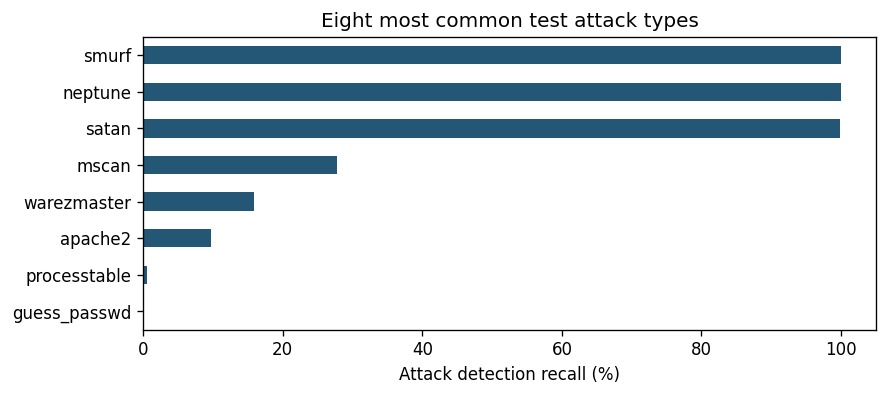

In [6]:
analysis = pd.DataFrame({'attack_name': test.attack_name, 'actual_attack': y_test, 'predicted_attack': y_pred})
subtypes = analysis.loc[analysis.actual_attack == 1].groupby('attack_name').agg(support=('predicted_attack', 'size'), detected=('predicted_attack', 'sum'))
subtypes['missed'] = subtypes['support'] - subtypes['detected']
subtypes['detection_recall'] = subtypes['detected'] / subtypes['support']
subtypes = subtypes.sort_values('support', ascending=False)
subtypes.to_csv(ROOT / 'results/attack_type_recall.csv')
analysis.to_csv(ROOT / 'results/test_predictions.csv', index=False)
print(subtypes.to_string())
fig, ax = plt.subplots(figsize=(7.5, 3.4))
subtypes.head(8).sort_values('detection_recall')['detection_recall'].mul(100).plot.barh(ax=ax, color='#245675')
ax.set(xlabel='Attack detection recall (%)', ylabel='', xlim=(0, 105), title='Eight most common test attack types')
fig.tight_layout()
fig.savefig(ROOT / 'images/attack_recall.png', dpi=170)
plt.show()
print(f'The model misses {fn:,} attacks ({metrics["miss_rate"]:.2%}). It can support an analyst, but it is not sufficient as the only defense.')


## 6 Save and demonstrate incoming-record prediction
Save preprocessing and classification together so predictions use the same transformations. The demo feeds ten existing test records one at a time. It represents the prediction stage of a real-time system only. Live packet capture, connection tracking and calculation of all 41 features are outside this prototype. The saved score is a model estimate, not a calibrated guarantee.

In [7]:
joblib.dump(model, ROOT / 'models/ids_pipeline.joblib', compress=3)
X_test.head(10).to_csv(ROOT / 'data/demo_features.csv', index=False)
(ROOT / 'models/feature_columns.json').write_text(json.dumps(FEATURES, indent=2))
restored = joblib.load(ROOT / 'models/ids_pipeline.joblib')
assert np.array_equal(restored.predict(X_test.head(10)), y_pred[:10])
# Only load joblib models from trusted sources.
replay_rows = []
print('SIMULATED STREAM: recorded features, no live packet capture')
for i in range(10):
    start = time.perf_counter()
    scores = restored.predict_proba(X_test.iloc[[i]])[0]
    prediction = int(restored.classes_[np.argmax(scores)])
    elapsed = (time.perf_counter() - start) * 1000
    result = {'record': i + 1, 'prediction': 'ATTACK' if prediction else 'NORMAL',
              'attack_score': float(scores[list(restored.classes_).index(1)]),
              'inference_ms': elapsed}
    replay_rows.append(result)
    print(f'{i+1:02d}  {result["prediction"]:6}  attack score={result["attack_score"]:.3f}  inference={elapsed:.1f} ms')
pd.DataFrame(replay_rows).to_csv(ROOT / 'results/replay_output.csv', index=False)
print('All results, charts and the saved pipeline are ready.')


SIMULATED STREAM: recorded features, no live packet capture
01  ATTACK  attack score=1.000  inference=17.3 ms
02  ATTACK  attack score=1.000  inference=28.5 ms
03  NORMAL  attack score=0.018  inference=27.5 ms
04  ATTACK  attack score=0.983  inference=17.5 ms
05  NORMAL  attack score=0.283  inference=27.9 ms
06  NORMAL  attack score=0.000  inference=29.4 ms
07  NORMAL  attack score=0.023  inference=19.4 ms
08  NORMAL  attack score=0.102  inference=16.6 ms
09  NORMAL  attack score=0.000  inference=17.4 ms
10  NORMAL  attack score=0.114  inference=16.2 ms
All results, charts and the saved pipeline are ready.


## 7 Conclusion and next steps
The measured results show useful detection, but missed attacks prevent stand-alone deployment. The older dataset, uncommon attack types and different training/test patterns limit generalization. Keep the firewall and existing IDS. Next, use a modern dataset, compare models with a training-only validation split, improve rare-attack coverage, calibrate scores and test an authorized live feature collector. Do not tune against the held-out test set.

### References
- UNB Canadian Institute for Cybersecurity: https://www.unb.ca/cic/datasets/nsl.html
- M. Tavallaee et al., *A Detailed Analysis of the KDD CUP 99 Data Set*, IEEE CISDA, 2009, DOI: 10.1109/CISDA.2009.5356528.
- UCI feature definitions: https://kdd.ics.uci.edu/databases/kddcup99/task.html
- Dataset mirror: https://github.com/jmnwong/NSL-KDD-Dataset
- scikit-learn: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- Project: https://github.com/moazsarwar2004/Network-Intrusion-Detection_
